# T5 – Object Detection on the Banana Detection Dataset
**Course:** Deep Learning for Computer Vision | **Unit 3:** Object Detection and Bounding Boxes, Anchor Boxes, Multiscale Object Detection

## Aim
To demonstrate an object detection model (a Single Shot Multibox Detector, SSD) that detects the position and class of a banana in an image, using the Banana Detection dataset.

## Concepts used in this experiment
| Syllabus topic | Where it appears in this notebook |
|---|---|
| Object detection and bounding boxes | Dataset labels `(class, xmin, ymin, xmax, ymax)`, Section 2 |
| Anchor boxes | `multibox_prior`, `assign_anchor_to_bbox`, `multibox_target`, Sections 3–4 |
| Intersection over Union (IoU) | `box_iou` used for anchor assignment and for evaluation |
| Multiscale object detection | 5 feature-map scales in `TinySSD`, Section 5 |
| Non-maximum suppression (NMS) | `multibox_detection`, Section 4 |

## Algorithm (summary)
1. Load the dataset (1000 training and 100 validation images, one banana each).
2. Generate anchor boxes at every pixel of 5 feature maps (sizes and aspect ratios are different at each scale).
3. Label each anchor: *class* (background/banana) and *offset* to the ground-truth box (assigned by IoU).
4. Train a CNN to predict class and offset for every anchor. Loss = cross-entropy (class) + L1 (offset).
5. At test time, decode the offsets, apply NMS and display the best box.

In [1]:
import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torchvision.ops import box_iou, nms

torch.manual_seed(0)
np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch :', torch.__version__)
print('Device  :', device, '-', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU (training will be slow)')

PyTorch : 2.11.0+cu130
Device  : cuda - Tesla T4


## 2. Dataset: download, load and visualise
The Banana Detection dataset (from the *Dive into Deep Learning* project) has 1000 training and 100 validation images (256×256).
Each image contains one banana. `label.csv` stores `img_name, label, xmin, ymin, xmax, ymax` (pixel coordinates).

In [2]:
URL = 'http://d2l-data.s3-accelerate.amazonaws.com/banana-detection.zip'
DATA_ROOT = 'data'
data_dir = os.path.join(DATA_ROOT, 'banana-detection')

if not os.path.isdir(data_dir):
    os.makedirs(DATA_ROOT, exist_ok=True)
    zip_path = os.path.join(DATA_ROOT, 'banana-detection.zip')
    print('Downloading dataset ...')
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_ROOT)
print('Dataset folder :', data_dir)
print('Contents       :', os.listdir(data_dir))

Dataset folder : data/banana-detection
Contents       : ['.DS_Store', 'bananas_train', '._.DS_Store', 'bananas_val']


In [3]:
class BananasDataset(torch.utils.data.Dataset):
    """Returns (image [3,256,256] float in 0..1, label [1,5] = (class, xmin, ymin, xmax, ymax) scaled to 0..1)."""
    def __init__(self, is_train):
        split = 'bananas_train' if is_train else 'bananas_val'
        csv_data = pd.read_csv(os.path.join(data_dir, split, 'label.csv')).set_index('img_name')
        self.images, targets = [], []
        for img_name, row in csv_data.iterrows():
            path = os.path.join(data_dir, split, 'images', f'{img_name}')
            self.images.append(torchvision.io.read_image(path, torchvision.io.ImageReadMode.RGB))
            targets.append(list(row))
        targets = torch.tensor(targets, dtype=torch.float32)       # (N, 5)
        targets[:, 1:] = targets[:, 1:] / 256                      # normalise box to [0, 1]
        self.labels = targets.unsqueeze(1)                         # (N, 1, 5)
        print(f'read {len(self.images)} {"training" if is_train else "validation"} examples')

    def __getitem__(self, idx):
        return self.images[idx].float() / 255.0, self.labels[idx]

    def __len__(self):
        return len(self.images)


def load_data_bananas(batch_size):
    train_iter = torch.utils.data.DataLoader(BananasDataset(True), batch_size, shuffle=True)
    val_iter = torch.utils.data.DataLoader(BananasDataset(False), batch_size)
    return train_iter, val_iter


batch_size = 32
train_iter, val_iter = load_data_bananas(batch_size)
imgs, labels = next(iter(train_iter))
print('Image batch shape :', tuple(imgs.shape))
print('Label batch shape :', tuple(labels.shape), '-> (batch, objects per image, [class, xmin, ymin, xmax, ymax])')

read 1000 training examples
read 100 validation examples
Image batch shape : (32, 3, 256, 256)
Label batch shape : (32, 1, 5) -> (batch, objects per image, [class, xmin, ymin, xmax, ymax])


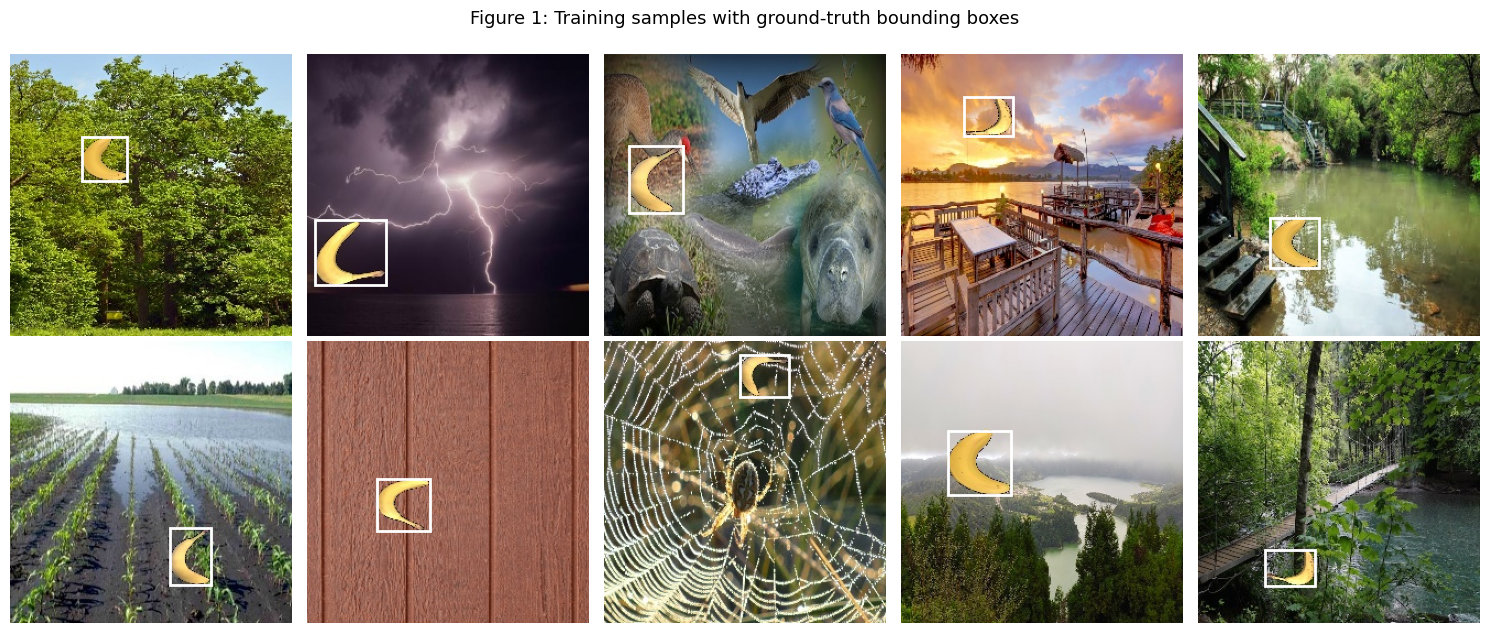

In [4]:
def show_boxes(ax, box, color='b', label=None):
    """box = (xmin, ymin, xmax, ymax) in pixels."""
    rect = patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                             linewidth=2, edgecolor=color, facecolor='none')
    ax.add_patch(rect)
    if label:
        ax.text(box[0], box[1], label, color='white', fontsize=8, va='bottom', ha='left',
                bbox=dict(facecolor=color, edgecolor=color, pad=1))


fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(imgs[i].permute(1, 2, 0).numpy())
    show_boxes(ax, labels[i, 0, 1:].numpy() * 256, 'w')
    ax.axis('off')
fig.suptitle('Figure 1: Training samples with ground-truth bounding boxes', fontsize=13)
plt.tight_layout()
plt.show()

## 3. Anchor boxes
For an input feature map of height *h* and width *w*, every pixel is the centre of several anchor boxes.
With sizes `s1..sn` and aspect ratios `r1..rm`, we only use combinations that include `s1` or `r1`, giving **n + m − 1** anchors per pixel.
Width = s·√r·(h/w), height = s/√r (all in normalised coordinates).

In [5]:
def multibox_prior(data, sizes, ratios):
    """Generate anchor boxes centred on every pixel of `data` (shape [B, C, H, W]).
    Returns tensor of shape (1, H*W*boxes_per_pixel, 4) in (xmin, ymin, xmax, ymax), normalised to [0, 1]."""
    in_height, in_width = data.shape[-2:]
    dev = data.device
    num_sizes, num_ratios = len(sizes), len(ratios)
    boxes_per_pixel = num_sizes + num_ratios - 1
    size_tensor = torch.tensor(sizes, device=dev)
    ratio_tensor = torch.tensor(ratios, device=dev)

    center_h = (torch.arange(in_height, device=dev) + 0.5) / in_height
    center_w = (torch.arange(in_width, device=dev) + 0.5) / in_width
    shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing='ij')
    shift_y, shift_x = shift_y.reshape(-1), shift_x.reshape(-1)

    w = torch.cat((size_tensor * torch.sqrt(ratio_tensor[0]),
                   sizes[0] * torch.sqrt(ratio_tensor[1:]))) * in_height / in_width
    h = torch.cat((size_tensor / torch.sqrt(ratio_tensor[0]),
                   sizes[0] / torch.sqrt(ratio_tensor[1:])))
    anchor_manipulations = torch.stack((-w, -h, w, h)).T.repeat(in_height * in_width, 1) / 2
    out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0)
    return (out_grid + anchor_manipulations).unsqueeze(0)


# Demonstration on a small feature map
demo_img = torch.zeros(1, 3, 561, 728)
demo_anchors = multibox_prior(demo_img, sizes=[0.75, 0.5, 0.25], ratios=[1, 2, 0.5])
print('Anchor tensor shape:', tuple(demo_anchors.shape), '(= 561 x 728 pixels x 5 anchors per pixel x 4 coordinates)')

Anchor tensor shape: (1, 2042040, 4) (= 561 x 728 pixels x 5 anchors per pixel x 4 coordinates)


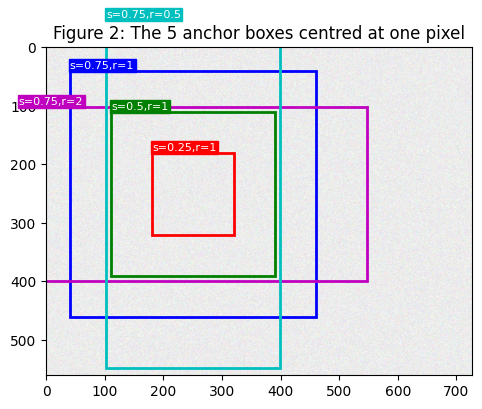

In [6]:
# Visualise anchors centred at one pixel
H, W = 561, 728
boxes = demo_anchors.reshape(H, W, 5, 4)[250, 250, :, :] * torch.tensor([W, H, W, H])
rand_img = np.random.rand(H, W, 3) * 0.15 + 0.85
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(rand_img)
colors = ['b', 'g', 'r', 'm', 'c']
names = ['s=0.75,r=1', 's=0.5,r=1', 's=0.25,r=1', 's=0.75,r=2', 's=0.75,r=0.5']
for b, c, n in zip(boxes, colors, names):
    show_boxes(ax, b.numpy(), c, n)
ax.set_title('Figure 2: The 5 anchor boxes centred at one pixel')
plt.show()

### 3.1 Intersection over Union (IoU)
$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}$$
IoU measures how well an anchor overlaps a ground-truth box. We use `torchvision.ops.box_iou`.

In [7]:
a = torch.tensor([[0.0, 0.0, 0.5, 0.5]])
b = torch.tensor([[0.25, 0.25, 0.75, 0.75]])
print('IoU example (expected 0.1429):', round(box_iou(a, b).item(), 4))

IoU example (expected 0.1429): 0.1429


## 4. Labelling anchors for training, and decoding predictions
* **Assignment:** each anchor is assigned the ground-truth box with the highest IoU (if IoU ≥ 0.5). In addition, each ground-truth box is guaranteed at least one anchor (the one with maximum IoU).
* **Class label:** 0 = background, 1 = banana.
* **Offset label** (relative to its anchor, with the standard scaling factors 10 and 5):
$$\left(\frac{x_{gt}-x_a}{w_a}\cdot 10,\; \frac{y_{gt}-y_a}{h_a}\cdot 10,\; 5\ln\frac{w_{gt}}{w_a},\; 5\ln\frac{h_{gt}}{h_a}\right)$$

In [8]:
def box_corner_to_center(boxes):
    x1, y1, x2, y2 = boxes.unbind(-1)
    return torch.stack(((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1), dim=-1)


def box_center_to_corner(boxes):
    cx, cy, w, h = boxes.unbind(-1)
    return torch.stack((cx - 0.5 * w, cy - 0.5 * h, cx + 0.5 * w, cy + 0.5 * h), dim=-1)


def assign_anchor_to_bbox(ground_truth, anchors, dev, iou_threshold=0.5):
    """For each anchor return the index of the assigned ground-truth box, or -1 (background)."""
    num_anchors, num_gt = anchors.shape[0], ground_truth.shape[0]
    jaccard = box_iou(anchors, ground_truth)                              # (num_anchors, num_gt)
    anchors_bbox_map = torch.full((num_anchors,), -1, dtype=torch.long, device=dev)
    max_ious, indices = torch.max(jaccard, dim=1)
    anc_i = torch.nonzero(max_ious >= iou_threshold).reshape(-1)
    box_j = indices[max_ious >= iou_threshold]
    anchors_bbox_map[anc_i] = box_j
    col_discard = torch.full((num_anchors,), -1.0, device=dev)
    row_discard = torch.full((num_gt,), -1.0, device=dev)
    for _ in range(num_gt):                                               # guarantee every GT gets an anchor
        max_idx = torch.argmax(jaccard)
        box_idx = (max_idx % num_gt).long()
        anc_idx = (max_idx // num_gt).long()
        anchors_bbox_map[anc_idx] = box_idx
        jaccard[:, box_idx] = col_discard
        jaccard[anc_idx, :] = row_discard
    return anchors_bbox_map


def offset_boxes(anchors, assigned_bb, eps=1e-6):
    c_anc = box_corner_to_center(anchors)
    c_assigned = box_corner_to_center(assigned_bb)
    offset_xy = 10 * (c_assigned[:, :2] - c_anc[:, :2]) / c_anc[:, 2:]
    offset_wh = 5 * torch.log(eps + c_assigned[:, 2:] / c_anc[:, 2:])
    return torch.cat([offset_xy, offset_wh], dim=1)


def multibox_target(anchors, labels):
    """anchors: (1, A, 4); labels: (B, num_gt, 5).
    Returns (bbox_offset (B, A*4), bbox_mask (B, A*4), class_labels (B, A))."""
    batch_size = labels.shape[0]
    anchors = anchors.squeeze(0)
    num_anchors, dev = anchors.shape[0], anchors.device
    batch_offset, batch_mask, batch_class_labels = [], [], []
    for i in range(batch_size):
        label = labels[i]
        anchors_bbox_map = assign_anchor_to_bbox(label[:, 1:], anchors, dev)
        pos = anchors_bbox_map >= 0
        bbox_mask = pos.float().unsqueeze(-1).repeat(1, 4)
        class_labels = torch.zeros(num_anchors, dtype=torch.long, device=dev)
        assigned_bb = torch.zeros((num_anchors, 4), dtype=torch.float32, device=dev)
        idx_true = torch.nonzero(pos).squeeze(-1)
        bb_idx = anchors_bbox_map[idx_true]
        class_labels[idx_true] = label[bb_idx, 0].long() + 1              # 0 is background
        assigned_bb[idx_true] = label[bb_idx, 1:]
        offset = offset_boxes(anchors, assigned_bb) * bbox_mask
        batch_offset.append(offset.reshape(-1))
        batch_mask.append(bbox_mask.reshape(-1))
        batch_class_labels.append(class_labels)
    return torch.stack(batch_offset), torch.stack(batch_mask), torch.stack(batch_class_labels)


def offset_inverse(anchors, offset_preds):
    """Decode predicted offsets back to corner-format boxes."""
    anc = box_corner_to_center(anchors)
    pred_xy = offset_preds[:, :2] * anc[:, 2:] / 10 + anc[:, :2]
    pred_wh = torch.exp(offset_preds[:, 2:] / 5) * anc[:, 2:]
    return box_center_to_corner(torch.cat((pred_xy, pred_wh), dim=1))


def multibox_detection(cls_probs, offset_preds, anchors, nms_threshold=0.5, pos_threshold=0.01):
    """cls_probs: (B, num_classes+1, A); offset_preds: (B, A*4); anchors: (1, A, 4).
    Returns a list (one entry per image) of tensors (k, 6) = [class_id, confidence, xmin, ymin, xmax, ymax],
    sorted by confidence after non-maximum suppression."""
    anchors = anchors.squeeze(0)
    results = []
    for i in range(cls_probs.shape[0]):
        conf, class_id = torch.max(cls_probs[i, 1:], dim=0)               # best foreground class per anchor
        boxes = offset_inverse(anchors, offset_preds[i].reshape(-1, 4))
        keep = nms(boxes, conf, nms_threshold)                            # NMS removes duplicate detections
        keep = keep[conf[keep] > pos_threshold]
        results.append(torch.cat([class_id[keep].float().unsqueeze(1),
                                  conf[keep].unsqueeze(1), boxes[keep]], dim=1))
    return results

**Sanity test of the labelling function** (two ground-truth boxes, five anchors – a standard textbook example).

In [9]:
ground_truth = torch.tensor([[0, 0.1, 0.08, 0.52, 0.92],
                             [1, 0.55, 0.2, 0.9, 0.88]])
anchors_t = torch.tensor([[0, 0.1, 0.2, 0.3], [0.15, 0.3, 0.4, 0.4],
                          [0.63, 0.05, 0.88, 0.98], [0.66, 0.45, 0.8, 0.8],
                          [0.57, 0.3, 0.92, 0.9]])
off, mask, cls = multibox_target(anchors_t.unsqueeze(0), ground_truth.unsqueeze(0))
print('Class labels of the 5 anchors (0 = background):', cls[0].tolist())
print('Mask (1 = anchor is positive)                 :', mask[0].reshape(-1, 4)[:, 0].tolist())
print('Offsets of anchor 4 (index 4)                 :', [round(v, 2) for v in off[0].reshape(-1, 4)[4].tolist()])

Class labels of the 5 anchors (0 = background): [0, 1, 2, 0, 2]
Mask (1 = anchor is positive)                 : [0.0, 1.0, 1.0, 0.0, 1.0]
Offsets of anchor 4 (index 4)                 : [-0.57, -1.0, 0.0, 0.63]


## 5. Model: Tiny SSD with multiscale detection
* **Base network** – 3 down-sampling blocks (each: 2×[Conv3×3-BN-ReLU] + MaxPool) → 32×32 feature map, 64 channels.
* **Blocks 1–3** – further down-sampling → 16×16, 8×8, 4×4 maps (128 channels).
* **Block 4** – global max pooling → 1×1 map.
* At each of the **5 scales** a class predictor and a bounding-box predictor (3×3 convolutions) are attached. Small feature maps (large receptive field) detect large objects; large maps detect small objects – this is **multiscale object detection**.
* Anchors per pixel = 2 sizes + 3 ratios − 1 = 4, giving 32²·4 + 16²·4 + 8²·4 + 4²·4 + 1·4 = **5444 anchors** per image.

In [10]:
def cls_predictor(num_inputs, num_anchors, num_classes):
    return nn.Conv2d(num_inputs, num_anchors * (num_classes + 1), kernel_size=3, padding=1)


def bbox_predictor(num_inputs, num_anchors):
    return nn.Conv2d(num_inputs, num_anchors * 4, kernel_size=3, padding=1)


def flatten_pred(pred):
    return torch.flatten(pred.permute(0, 2, 3, 1), start_dim=1)


def concat_preds(preds):
    return torch.cat([flatten_pred(p) for p in preds], dim=1)


def down_sample_blk(in_channels, out_channels):
    blk = []
    for _ in range(2):
        blk.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
        blk.append(nn.BatchNorm2d(out_channels))
        blk.append(nn.ReLU())
        in_channels = out_channels
    blk.append(nn.MaxPool2d(2))
    return nn.Sequential(*blk)


def base_net():
    num_filters = [3, 16, 32, 64]
    return nn.Sequential(*[down_sample_blk(num_filters[i], num_filters[i + 1])
                           for i in range(len(num_filters) - 1)])


def get_blk(i):
    if i == 0:
        return base_net()
    elif i == 1:
        return down_sample_blk(64, 128)
    elif i == 4:
        return nn.AdaptiveMaxPool2d((1, 1))
    return down_sample_blk(128, 128)


def blk_forward(X, blk, size, ratio, cls_pred, bbox_pred):
    Y = blk(X)
    anchors = multibox_prior(Y, sizes=size, ratios=ratio)
    return Y, anchors, cls_pred(Y), bbox_pred(Y)


sizes = [[0.2, 0.272], [0.37, 0.447], [0.54, 0.619], [0.71, 0.79], [0.88, 0.961]]
ratios = [[1, 2, 0.5]] * 5
num_anchors_per_pixel = len(sizes[0]) + len(ratios[0]) - 1


class TinySSD(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.num_classes = num_classes
        in_channels = [64, 128, 128, 128, 128]
        for i in range(5):
            setattr(self, f'blk_{i}', get_blk(i))
            setattr(self, f'cls_{i}', cls_predictor(in_channels[i], num_anchors_per_pixel, num_classes))
            setattr(self, f'bbox_{i}', bbox_predictor(in_channels[i], num_anchors_per_pixel))

    def forward(self, X):
        anchors, cls_preds, bbox_preds = [None] * 5, [None] * 5, [None] * 5
        for i in range(5):
            X, anchors[i], cls_preds[i], bbox_preds[i] = blk_forward(
                X, getattr(self, f'blk_{i}'), sizes[i], ratios[i],
                getattr(self, f'cls_{i}'), getattr(self, f'bbox_{i}'))
        anchors = torch.cat(anchors, dim=1)
        cls_preds = concat_preds(cls_preds).reshape(X.shape[0], -1, self.num_classes + 1)
        bbox_preds = concat_preds(bbox_preds)
        return anchors, cls_preds, bbox_preds


net = TinySSD(num_classes=1).to(device)
with torch.no_grad():
    anchors_o, cls_o, bbox_o = net(torch.zeros(32, 3, 256, 256, device=device))
print('Output anchors shape    :', tuple(anchors_o.shape))
print('Output class preds shape:', tuple(cls_o.shape))
print('Output bbox preds shape :', tuple(bbox_o.shape))
print('Trainable parameters    :', sum(p.numel() for p in net.parameters() if p.requires_grad))

Output anchors shape    : (1, 5444, 4)
Output class preds shape: (32, 5444, 2)
Output bbox preds shape : (32, 21776)
Trainable parameters    : 1010376


## 6. Loss function and evaluation metrics
* **Class loss:** cross-entropy over all anchors.
* **Offset loss:** L1 loss, multiplied by the mask so that only positive anchors contribute.
* **Metrics:** classification error rate of anchors, offset MAE, and (on validation images) the **IoU of the top detection** and the percentage of images with IoU ≥ 0.5.

In [11]:
cls_loss = nn.CrossEntropyLoss(reduction='none')
bbox_loss = nn.L1Loss(reduction='none')


def calc_loss(cls_preds, cls_labels, bbox_preds, bbox_labels, bbox_masks):
    batch_size, num_classes = cls_preds.shape[0], cls_preds.shape[2]
    cls = cls_loss(cls_preds.reshape(-1, num_classes), cls_labels.reshape(-1)).reshape(batch_size, -1).mean(dim=1)
    bbox = bbox_loss(bbox_preds * bbox_masks, bbox_labels * bbox_masks).mean(dim=1)
    return cls + bbox


def cls_eval(cls_preds, cls_labels):
    return float((cls_preds.argmax(dim=-1).type(cls_labels.dtype) == cls_labels).sum())


def bbox_eval(bbox_preds, bbox_labels, bbox_masks):
    return float((torch.abs((bbox_labels - bbox_preds) * bbox_masks)).sum())


@torch.no_grad()
def evaluate(net, data_iter):
    """Returns (anchor class error, offset MAE, mean IoU of top detection, % images with IoU>=0.5)."""
    net.eval()
    n_cls_ok = n_cls = bbox_abs = n_bbox = 0.0
    ious = []
    for X, Y in data_iter:
        X, Y = X.to(device), Y.to(device)
        anchors, cls_preds, bbox_preds = net(X)
        bbox_labels, bbox_masks, cls_labels = multibox_target(anchors, Y)
        n_cls_ok += cls_eval(cls_preds, cls_labels); n_cls += cls_labels.numel()
        bbox_abs += bbox_eval(bbox_preds, bbox_labels, bbox_masks); n_bbox += bbox_labels.numel()
        probs = F.softmax(cls_preds, dim=2).permute(0, 2, 1)
        dets = multibox_detection(probs, bbox_preds, anchors)
        for det, gt in zip(dets, Y):
            ious.append(box_iou(det[:1, 2:], gt[:, 1:]).item() if len(det) > 0 else 0.0)
    ious = np.array(ious)
    return 1 - n_cls_ok / n_cls, bbox_abs / n_bbox, ious.mean(), (ious >= 0.5).mean() * 100

## 7. Training
SGD with learning rate 0.2, weight decay 5e-4, batch size 32, 20 epochs.

In [12]:
num_epochs = 20
trainer = torch.optim.SGD(net.parameters(), lr=0.2, weight_decay=5e-4)
history = {'cls_err': [], 'bbox_mae': [], 'val_cls_err': [], 'val_bbox_mae': [], 'val_iou': [], 'val_acc50': []}

print(f"{'Epoch':>5} | {'Train cls err':>13} | {'Train bbox MAE':>14} | {'Val cls err':>11} | {'Val mean IoU':>12} | {'IoU>=0.5 (%)':>12} | {'Time (s)':>8}")
print('-' * 98)
start = time.time()
for epoch in range(num_epochs):
    net.train()
    t0 = time.time()
    ok = tot = babs = bn = 0.0
    for X, Y in train_iter:
        X, Y = X.to(device), Y.to(device)
        trainer.zero_grad()
        anchors, cls_preds, bbox_preds = net(X)
        bbox_labels, bbox_masks, cls_labels = multibox_target(anchors, Y)
        l = calc_loss(cls_preds, cls_labels, bbox_preds, bbox_labels, bbox_masks)
        l.mean().backward()
        trainer.step()
        ok += cls_eval(cls_preds, cls_labels); tot += cls_labels.numel()
        babs += bbox_eval(bbox_preds, bbox_labels, bbox_masks); bn += bbox_labels.numel()
    tr_cls_err, tr_bbox_mae = 1 - ok / tot, babs / bn
    v_cls_err, v_bbox_mae, v_iou, v_acc = evaluate(net, val_iter)
    for k, v in zip(history, [tr_cls_err, tr_bbox_mae, v_cls_err, v_bbox_mae, v_iou, v_acc]):
        history[k].append(v)
    print(f'{epoch + 1:>5} | {tr_cls_err:>13.5f} | {tr_bbox_mae:>14.5f} | {v_cls_err:>11.5f} | {v_iou:>12.4f} | {v_acc:>12.1f} | {time.time() - t0:>8.1f}')
print(f'\nTotal training time: {time.time() - start:.1f} s on {device}')

Epoch | Train cls err | Train bbox MAE | Val cls err | Val mean IoU | IoU>=0.5 (%) | Time (s)
--------------------------------------------------------------------------------------------------


/tmp/ipykernel_601/225039545.py:17: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return float((torch.abs((bbox_labels - bbox_preds) * bbox_masks)).sum())


    1 |       0.02103 |        0.00546 |     0.00497 |       0.0422 |          0.0 |      8.0
    2 |       0.00500 |        0.00503 |     0.00482 |       0.0429 |          0.0 |      6.5
    3 |       0.00486 |        0.00487 |     0.00479 |       0.0907 |          8.0 |      6.6
    4 |       0.00484 |        0.00470 |     0.00477 |       0.5486 |         78.0 |      6.6
    5 |       0.00473 |        0.00454 |     0.00446 |       0.6063 |         87.0 |      6.5
    6 |       0.00451 |        0.00435 |     0.00439 |       0.6273 |         91.0 |      6.5
    7 |       0.00431 |        0.00420 |     0.00469 |       0.5702 |         79.0 |      7.2
    8 |       0.00408 |        0.00409 |     0.00383 |       0.6526 |         90.0 |      6.5
    9 |       0.00381 |        0.00401 |     0.00416 |       0.6567 |         90.0 |      6.6
   10 |       0.00372 |        0.00392 |     0.01056 |       0.6716 |         91.0 |      6.6
   11 |       0.00363 |        0.00383 |     0.00686 |      

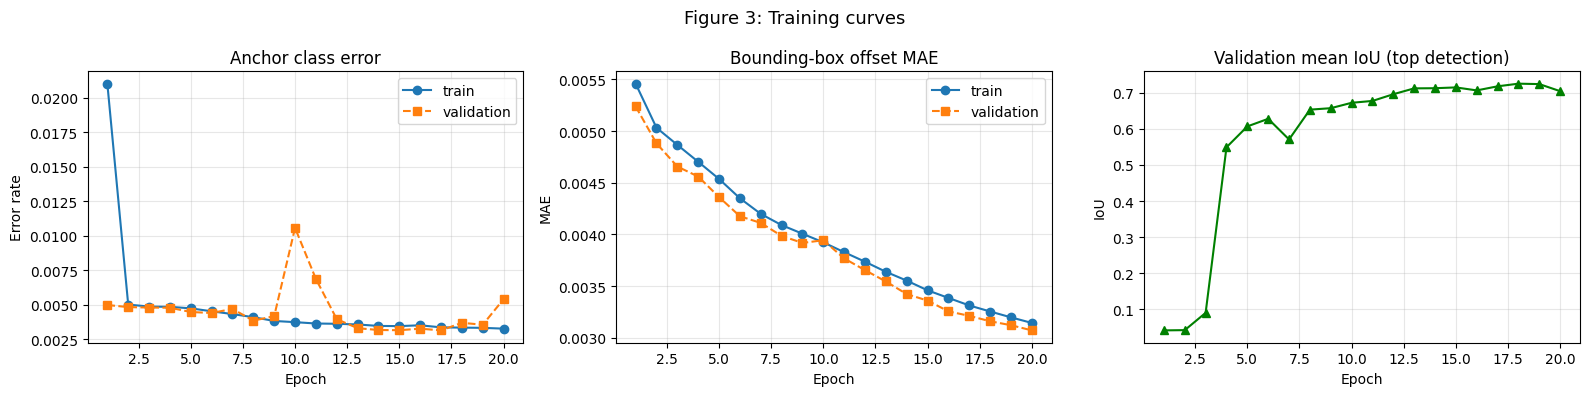

In [13]:
epochs = range(1, num_epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(epochs, history['cls_err'], 'o-', label='train'); axes[0].plot(epochs, history['val_cls_err'], 's--', label='validation')
axes[0].set(title='Anchor class error', xlabel='Epoch', ylabel='Error rate'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(epochs, history['bbox_mae'], 'o-', label='train'); axes[1].plot(epochs, history['val_bbox_mae'], 's--', label='validation')
axes[1].set(title='Bounding-box offset MAE', xlabel='Epoch', ylabel='MAE'); axes[1].legend(); axes[1].grid(alpha=.3)
axes[2].plot(epochs, history['val_iou'], 'g^-')
axes[2].set(title='Validation mean IoU (top detection)', xlabel='Epoch', ylabel='IoU'); axes[2].grid(alpha=.3)
fig.suptitle('Figure 3: Training curves', fontsize=13)
plt.tight_layout()
plt.show()

## 8. Results: testing the trained detector
Final validation metrics, then predictions on validation images
(**green** = ground truth, **red** = predicted box with confidence score).

In [14]:
v_cls_err, v_bbox_mae, v_iou, v_acc = evaluate(net, val_iter)
print('FINAL VALIDATION RESULTS')
print(f'  Anchor classification error : {v_cls_err:.5f}')
print(f'  Offset MAE                  : {v_bbox_mae:.5f}')
print(f'  Mean IoU (top-1 detection)  : {v_iou:.4f}')
print(f'  Images with IoU >= 0.5      : {v_acc:.1f} %')

FINAL VALIDATION RESULTS
  Anchor classification error : 0.00539
  Offset MAE                  : 0.00307
  Mean IoU (top-1 detection)  : 0.7037
  Images with IoU >= 0.5      : 96.0 %


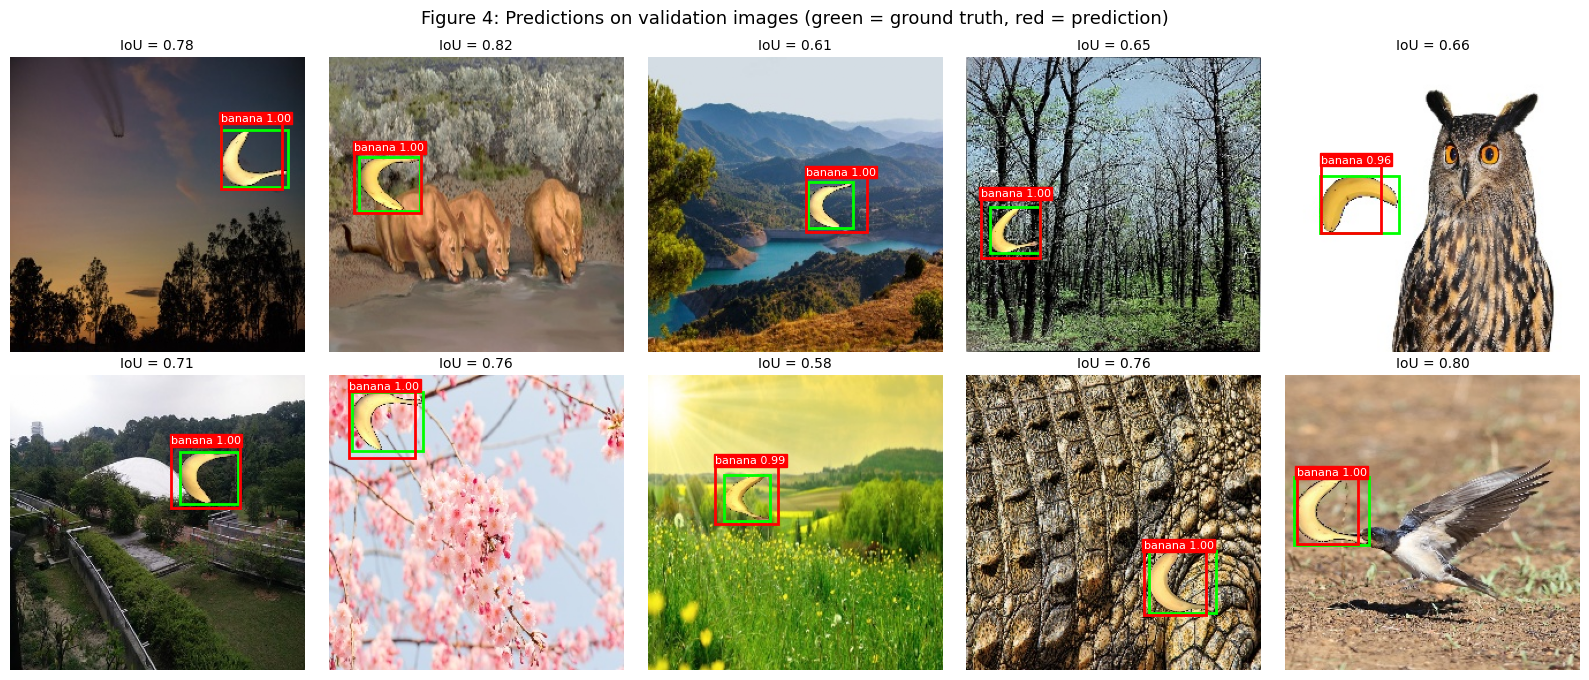

In [15]:
@torch.no_grad()
def predict(net, X, nms_threshold=0.5, pos_threshold=0.01):
    net.eval()
    anchors, cls_preds, bbox_preds = net(X.to(device))
    probs = F.softmax(cls_preds, dim=2).permute(0, 2, 1)
    return multibox_detection(probs, bbox_preds, anchors, nms_threshold, pos_threshold)


X_val, Y_val = next(iter(val_iter))
dets = predict(net, X_val[:10])

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_val[i].permute(1, 2, 0).numpy())
    show_boxes(ax, Y_val[i, 0, 1:].numpy() * 256, 'lime')
    if len(dets[i]) > 0:
        top = dets[i][0].cpu()
        iou = box_iou(top[None, 2:], Y_val[i, :, 1:]).item()
        show_boxes(ax, top[2:].numpy() * 256, 'red', f'banana {top[1]:.2f}')
        ax.set_title(f'IoU = {iou:.2f}', fontsize=10)
    ax.axis('off')
fig.suptitle('Figure 4: Predictions on validation images (green = ground truth, red = prediction)', fontsize=13)
plt.tight_layout()
plt.show()

## 9. Effect of Non-Maximum Suppression
Before NMS the network produces many overlapping boxes around the same banana. NMS keeps only the best one.

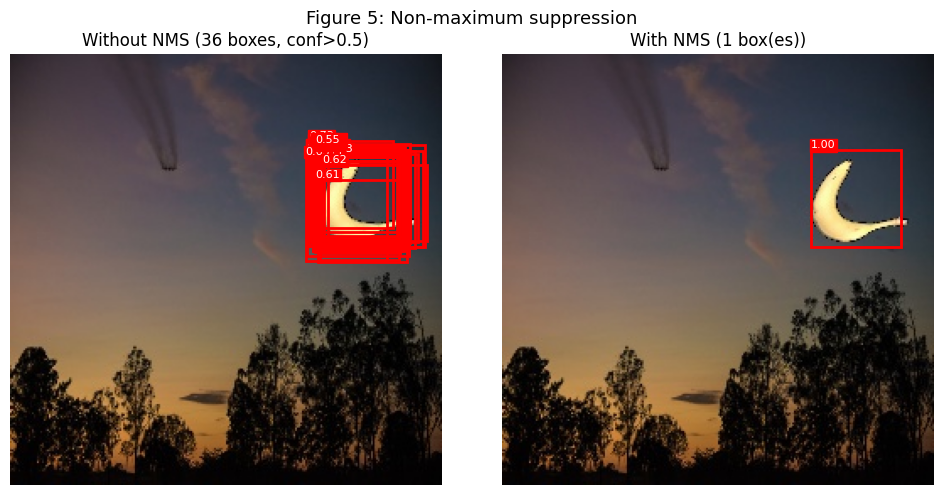

In [16]:
with torch.no_grad():
    net.eval()
    anchors, cls_preds, bbox_preds = net(X_val[:1].to(device))
    probs = F.softmax(cls_preds, dim=2).permute(0, 2, 1)
no_nms = multibox_detection(probs, bbox_preds, anchors, nms_threshold=1.0, pos_threshold=0.5)[0].cpu()
with_nms = multibox_detection(probs, bbox_preds, anchors, nms_threshold=0.5, pos_threshold=0.5)[0].cpu()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, det, title in zip(axes, [no_nms, with_nms], [f'Without NMS ({len(no_nms)} boxes, conf>0.5)', f'With NMS ({len(with_nms)} box(es))']):
    ax.imshow(X_val[0].permute(1, 2, 0).numpy())
    for d in det:
        show_boxes(ax, d[2:].numpy() * 256, 'red', f'{d[1]:.2f}')
    ax.set_title(title); ax.axis('off')
fig.suptitle('Figure 5: Non-maximum suppression', fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
torch.save(net.state_dict(), 'net_banana_ssd.pth')
print('Model saved to net_banana_ssd.pth')

Model saved to net_banana_ssd.pth


## 10. Result and conclusion
* A Tiny SSD with five-scale anchor boxes was trained end-to-end on the Banana Detection dataset.
* Anchor boxes at multiple scales and aspect ratios allow objects of different sizes to be matched; the IoU criterion assigns ground truth to anchors; NMS removes duplicate predictions.
* The training curves show the classification error and offset MAE decreasing with epochs, and the validation IoU table/figures show that the detector localises the banana accurately.

**Result:** The object detection model for the Banana Detection dataset was implemented and demonstrated successfully.

